# a sanity on the values of dbdt

In [20]:
from em1d.experiment import Loop, Receiver
import matplotlib.pyplot as plt
import numpy as np
from numpy.linalg import norm

In [21]:
from em1d.transforms import precalcHankel1, BaseHankel, BaseFourier, CubicSpline
from em1d.physics import refl_transverse_electric as rte, freespace_u0 as u0, mu0
from em1d.experiment import getRz
import torch
twopi = torch.pi*2

class Forward:
    def __init__(self, source, receiver, times, radius):
        self.source = source
        self.receiver = receiver
        self.times = torch.tensor(times)

        self.rmin = self.source.min_horizontal_distance(self.receiver)
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        # self.sofr = torch.tensor([0., 0., 2*np.pi*a], dtype=torch.complex128)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0])
        self.a = torch.tensor(a)

    def forward(self):
        def frq_integrand(omega):
            omega = omega[None,:,None]
            def integrand(wave_length):
                lmb = wave_length[None, None, :]
                tmp_u0 = u0(omega, lmb)
                intg = torch.squeeze((torch.exp(-tmp_u0*self.dz)*rte(self.sigma, self.thick, omega, lmb))*lmb**2 / tmp_u0)
                return intg
            
            hkl1 = BaseHankel(integrand, 1, smp_per_decade=20)
            r, hr = hkl1.range(self.rmin, self.rmax)
            hr *= r
            # sofr = -torch.tensor(self.source.s_of_r(self.receiver, r.numpy()), dtype=torch.complex128)
            cbhr = CubicSpline(r.real, hr.T, transform=torch.log)
            res = cbhr(self.a)
            # res = hr @ sofr
            return res
        f_t=BaseFourier(frq_integrand, smp_per_decade=20)
        t,dbdt = f_t.range(self.times[0], self.times[-1])        
        # print('shape of dbdt:', dbdt.shape)
        cbs = CubicSpline(t, dbdt, transform=torch.log)
        return cbs(self.times)/twopi/2

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
        self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]
        return self.forward()

In [22]:
ainv_dbdt=np.array([6.145711e-04, 3.319648e-04, 1.650304e-04, 8.868765e-05,
       4.967526e-05, 2.618016e-05, 1.444254e-05, 8.242962e-06,
       4.457639e-06, 2.520354e-06, 1.515021e-06, 8.744991e-07,
       4.584869e-07, 2.520399e-07, 1.447630e-07, 7.766509e-08,
       4.233407e-08, 2.387553e-08, 1.272288e-08, 6.846980e-09])

times = np.array([9.350e-06, 1.145e-05, 1.458e-05, 1.822e-05, 2.255e-05, 2.867e-05,
       3.595e-05, 4.460e-05, 5.660e-05, 7.070e-05, 8.630e-05, 1.071e-04,
       1.381e-04, 1.748e-04, 2.174e-04, 2.775e-04, 3.515e-04, 4.385e-04,
       5.575e-04, 7.035e-04])

In [23]:
radius = np.sqrt(40*40/np.pi)
# a=50

In [25]:
lp = Loop.circle(radius, n=100)
lp = Loop.square(40, z=0.02)
rx=Receiver(z=0.02)

rho = 40
sigma = 1/torch.tensor([rho,rho, rho, rho, rho])
thick = torch.tensor([1, 2, 20, 40])

# fwr = Forward(lp, rx, np.logspace(-9, -1, 51))
fwr = Forward(lp, rx, times, radius)
from time import perf_counter as timer
bt = timer()
dbdt = fwr(sigma, thick)
print(dbdt.shape)

C:\Users\au487220\AppData\Local\Temp\ipykernel_13232\2614095405.py:43: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
C:\Users\au487220\AppData\Local\Temp\ipykernel_13232\2614095405.py:44: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]


torch.Size([20])


C:\Users\au487220\OneDrive - Aarhus universitet\Documents\Repositories\em1d\src\em1d\transforms\transforms.py:236: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  rout = torch.tensor(10**(i_offsets/self.smp_per_decade), dtype=torch.complex128)
C:\Users\au487220\OneDrive - Aarhus universitet\Documents\Repositories\em1d\src\em1d\transforms\transforms.py:297: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  tout = torch.tensor(10**(i_offsets/self.smp_per_decade))


In [26]:
radii  = np.geomspace(1, radius, 5)
ratios = np.zeros_like(radii)
ratios_std = np.zeros_like(radii)

for ir,a in enumerate(radii):
    lp = Loop.circle(a, n=100)
    fwr = Forward(lp, rx, times, radius)
    dbdt = fwr(sigma, thick)
    from scipy.special import erf


    sgm = (1./rho)
    theta = np.sqrt(0.25*mu0*sgm / fwr.times.numpy())
    dhdt = 1./(mu0*sgm*a**3)*(3*erf(theta*a)-2*theta*a*(3+2*theta**2*a**2)*np.exp(-theta**2*a**2)/np.sqrt(np.pi))

    ratio = (dhdt.real/dbdt.real).cpu().numpy()
    ratios[ir] = ratio.mean()
    ratios_std[ir] = np.var(ratio)
ratios_std = np.sqrt(ratios_std)

C:\Users\au487220\AppData\Local\Temp\ipykernel_13232\2614095405.py:43: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
C:\Users\au487220\AppData\Local\Temp\ipykernel_13232\2614095405.py:44: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]


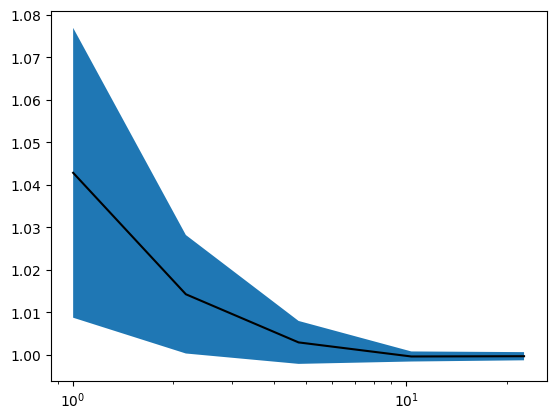

In [27]:
plt.figure()
plt.fill_between(radii, ratios-ratios_std, ratios+ratios_std)
plt.plot(radii, ratios, 'k-')
# plt.plot(radii, radii)
plt.xscale('log')
# plt.yscale('log')

In [28]:
20*np.sqrt(np.pi)

35.449077018110316

In [29]:
dhdt_lt = (1./40)**(3/2) * mu0**(3/2) * a**2 * fwr.times.numpy()**(-5/2) / (20*np.sqrt(np.pi))

In [30]:
1/8

0.125

In [31]:
from scipy.special import erf


sgm = (1./rho)
theta = np.sqrt(0.25*mu0*sgm / fwr.times.numpy())
dhdt = 1./(mu0*sgm*a**3)*(3*erf(theta*a)-2*theta*a*(3+2*theta**2*a**2)*np.exp(-theta**2*a**2)/np.sqrt(np.pi))

In [32]:
dhdt/np.abs(dbdt.real)

tensor([1.0014, 1.0012, 1.0010, 1.0008, 1.0007, 1.0005, 1.0003, 1.0001, 0.9999,
        0.9996, 0.9995, 0.9992, 0.9990, 0.9988, 0.9987, 0.9986, 0.9985, 0.9985,
        0.9986, 0.9988], dtype=torch.float64)

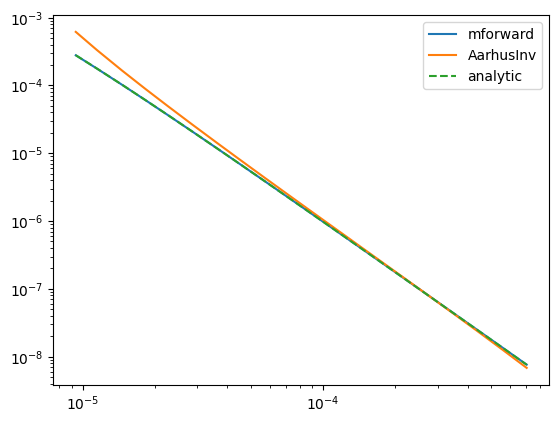

In [33]:
fig,ax = plt.subplots()
ax.loglog(fwr.times.numpy(), mu0*dbdt.real, label='mforward')
ax.loglog(times,      ainv_dbdt, label='AarhusInv')
ax.loglog(fwr.times.numpy(),       dhdt*mu0, '--', label='analytic')
# ax.loglog(fwr.times.numpy(),       dhdt_lt*mu0, '--', label='analytic1')
ax.legend()